In [1]:
import os
import pickle
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import ResNet50

In [2]:
DATASET_DIR = '/kaggle/input/datasets/macmillen0804/cifar-dataset/cifar-10-python'

DATASET_PATH = os.path.join(
    DATASET_DIR,
    'cifar-10-batches-py'
)

print(os.listdir(DATASET_PATH))

['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [3]:
meta_path = os.path.join(DATASET_PATH, 'batches.meta')

with open(meta_path, 'rb') as file:
    metadata = pickle.load(file, encoding='bytes')

class_names = [
    name.decode('utf-8')
    for name in metadata[b'label_names']
]
print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 10
0 : airplane
1 : automobile
2 : bird
3 : cat
4 : deer
5 : dog
6 : frog
7 : horse
8 : ship
9 : truck


##Load CIFAR-10 batches


In [4]:
def load_cifar_batch(file_path):

    with open(file_path, 'rb') as file:
        batch = pickle.load(file, encoding='bytes')

    images = batch[b'data']
    labels = batch[b'labels']

    # Reshape flattened images into RGB format
    images = images.reshape(-1, 3, 32, 32)

    # Convert channel order from CHW to HWC
    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)

##combining the five training batches into one dataset

In [5]:


# Lists to store images and labels
train_images = []
train_labels = []

# Load all five training batches
for i in range(1, 6):

    file_path = os.path.join(
        DATASET_PATH,
        f'data_batch_{i}'
    )

    images, labels = load_cifar_batch(file_path)

    train_images.append(images)
    train_labels.append(labels)

# Combine all batches
x_train_full = np.concatenate(train_images, axis=0)
y_train_full = np.concatenate(train_labels, axis=0)

print("Training images shape:", x_train_full.shape)
print("Training labels shape:", y_train_full.shape)

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000,)


In [6]:
#Load the test dataset
test_path = os.path.join(
    DATASET_PATH,
    'test_batch'
)

x_test, y_test = load_cifar_batch(test_path)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

Testing images shape: (10000, 32, 32, 3)
Testing labels shape: (10000,)


##Sample images

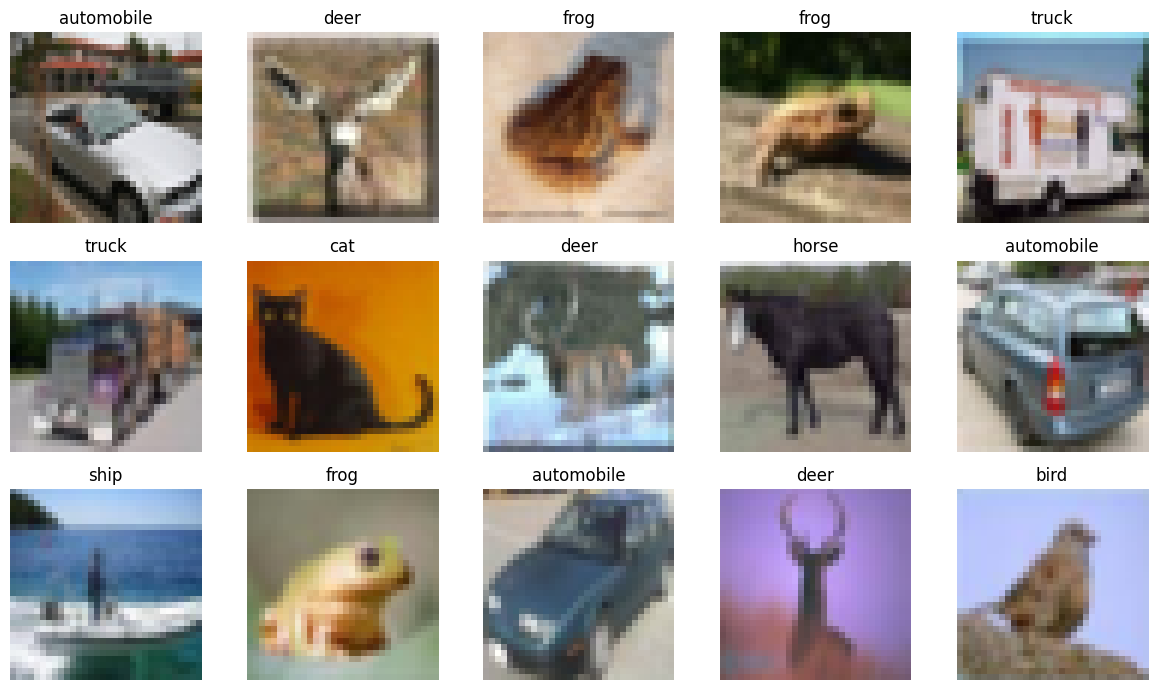

In [7]:
import numpy as np

plt.figure(figsize=(12, 7))

for i, idx in enumerate(np.random.choice(len(x_train_full), 15, replace=False)):

    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train_full[idx])

    label = y_train_full[idx]

    plt.title(class_names[label])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
# dataset inspection

print("Image shape:", x_train_full.shape)
print("Image data type:", x_train_full.dtype)

print("Minimum pixel value:", x_train_full.min())
print("Maximum pixel value:", x_train_full.max())

print("Number of training images:", len(x_train_full))
print("Number of testing images:", len(x_test))

print("Number of unique classes:",
      len(np.unique(y_train_full)))

Image shape: (50000, 32, 32, 3)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Number of training images: 50000
Number of testing images: 10000
Number of unique classes: 10


##Split the dataset into Training and Validation

In [9]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", x_val.shape)
print("Validation labels:", y_val.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (40000, 32, 32, 3)
Training labels: (40000,)
Validation images: (10000, 32, 32, 3)
Validation labels: (10000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [10]:
# Verification
print("Training class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_train == i))

print("\nValidation class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_val == i))

Training class distribution:
airplane : 4000
automobile : 4000
bird : 4000
cat : 4000
deer : 4000
dog : 4000
frog : 4000
horse : 4000
ship : 4000
truck : 4000

Validation class distribution:
airplane : 1000
automobile : 1000
bird : 1000
cat : 1000
deer : 1000
dog : 1000
frog : 1000
horse : 1000
ship : 1000
truck : 1000


In [11]:
#resizing images
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 10

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: 224
Batch size: 32
Number of classes: 10


In [12]:
sample_image = tf.image.resize(
    x_train[0],
    (IMG_SIZE, IMG_SIZE)
)

print("Original shape:", x_train[0].shape)
print("Resized shape:", sample_image.shape)

Original shape: (32, 32, 3)
Resized shape: (224, 224, 3)


##Build the pretrained ResNet50 model

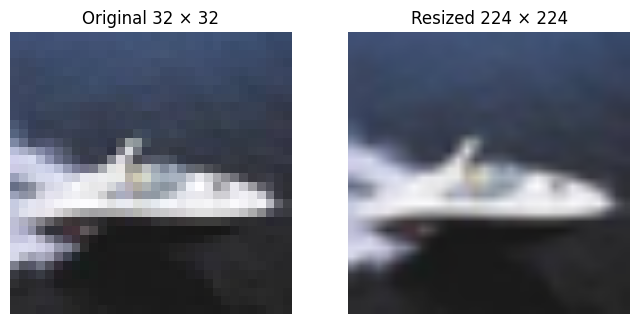

In [13]:
# Visualization of resized image
idx = np.random.randint(len(x_train))
sample_image = tf.image.resize(x_train[idx], (224, 224))

# Visualization of resized image
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(x_train[idx])
plt.title("Original 32 × 32")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_image.numpy().astype("uint8"))
plt.title("Resized 224 × 224")
plt.axis("off")

plt.show()

##Normalization

In [14]:
IMAGENET_MEAN = tf.constant(
    [0.485, 0.456, 0.406],
    dtype=tf.float32
)

IMAGENET_STD = tf.constant(
    [0.229, 0.224, 0.225],
    dtype=tf.float32
)

def normalize_image(image):

    image = tf.cast(image, tf.float32)

    image = image / 255.0

    image = (image - IMAGENET_MEAN) / IMAGENET_STD

    return image

In [15]:
# Testing
normalized_sample = normalize_image(sample_image)

print("Normalized image shape:", normalized_sample.shape)

print("Minimum value:",
      tf.reduce_min(normalized_sample).numpy())

print("Maximum value:",
      tf.reduce_max(normalized_sample).numpy())

Normalized image shape: (224, 224, 3)
Minimum value: -1.7582842
Maximum value: 2.6399994


##Data Augmentaton

In [16]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.ZeroPadding2D(
        padding=16
    ),

    tf.keras.layers.RandomCrop(
        IMG_SIZE,
        IMG_SIZE
    ),

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.1
    )

], name="data_augmentation")

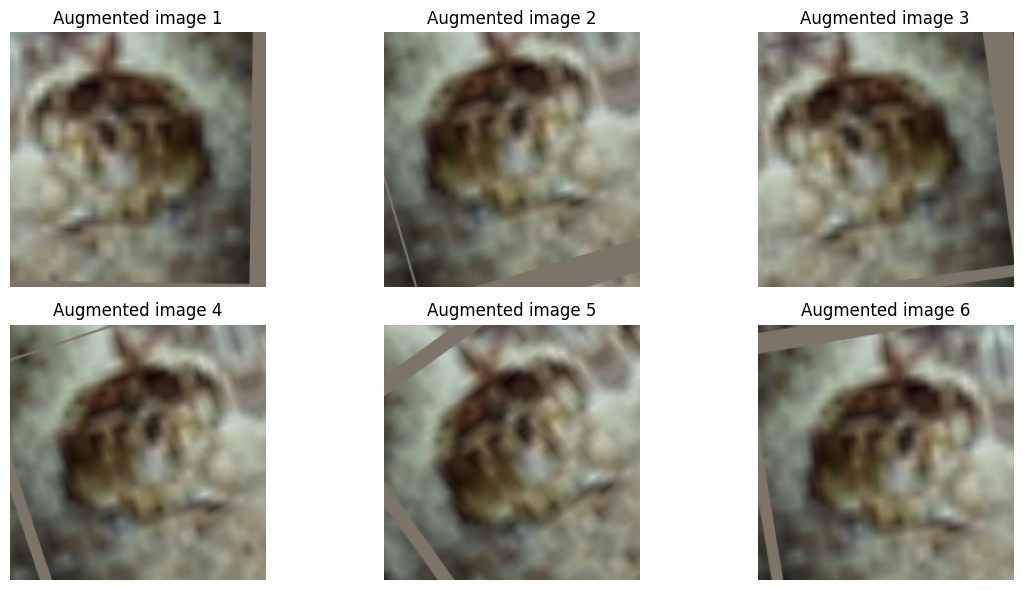

In [17]:
# Visulaizing  Resizing, normalization and augmentation one training image
sample = tf.image.resize(
    x_train[0],
    (IMG_SIZE, IMG_SIZE)
)

sample = normalize_image(sample)

plt.figure(figsize=(12, 6))

for i in range(6):

    augmented_image = data_augmentation(
        tf.expand_dims(sample, axis=0),
        training=True
    )

    augmented_image = augmented_image[0]

    # Convert normalized values back to displayable RGB
    display_image = augmented_image * IMAGENET_STD + IMAGENET_MEAN

    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.clip_by_value(display_image, 0, 1))
    plt.title(f"Augmented image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


##Pipeline for resizing, normalization and augmentation

In [18]:
def preprocess_image(image, label):

    # Resize image
    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    # ImageNet normalization
    image = normalize_image(image)

    return image, label

In [19]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_ds = train_ds.shuffle(
    buffer_size=10000,
    seed=42
)

train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE)

train_ds = train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.prefetch(
    tf.data.AUTOTUNE
)

In [20]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

val_ds = val_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)

val_ds = val_ds.prefetch(
    tf.data.AUTOTUNE
)


In [21]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_ds = test_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)

test_ds = test_ds.prefetch(
    tf.data.AUTOTUNE
)

In [22]:
for images, labels in train_ds.take(1):

    print("Training batch shape:", images.shape)
    print("Training labels shape:", labels.shape)

for images, labels in val_ds.take(1):

    print("Validation batch shape:", images.shape)

for images, labels in test_ds.take(1):

    print("Testing batch shape:", images.shape)

Training batch shape: (32, 224, 224, 3)
Training labels shape: (32,)
Validation batch shape: (32, 224, 224, 3)
Testing batch shape: (32, 224, 224, 3)


##Building the Transfer Learning Model

In [23]:
base_model = tf.keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [24]:
# Checking model
print("Total layers:", len(base_model.layers))
print("Input shape:", base_model.input_shape)
print("Output shape:", base_model.output_shape)

Total layers: 175
Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 2048)


##Feature Extraction

In [25]:
base_model.trainable = False
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Total layers:", len(base_model.layers))

Trainable layers: 0
Total layers: 175


In [26]:

# Freeze the pretrained ResNet50
base_model.trainable = False

# Input layer
inputs = layers.Input(shape=(224, 224, 3))

# Convert ImageNet mean/std normalized values back to RGB [0, 255]
x = layers.Lambda(
    lambda image: (image * IMAGENET_STD + IMAGENET_MEAN) * 255.0,
    name="reverse_normalization"
)(inputs)

# Apply the preprocessing expected by Keras ResNet50
x = layers.Lambda(
    tf.keras.applications.resnet.preprocess_input,
    name="resnet_preprocessing"
)(x)

# Extract features using pretrained ResNet50
x = base_model(x, training=False)

# Global Average Pooling
x = layers.GlobalAveragePooling2D()(x)

# Fully connected layer
x = layers.Dense(
    512,
    kernel_initializer="he_normal",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

# Batch Normalization
x = layers.BatchNormalization()(x)

# ReLU activation
x = layers.Activation("relu")(x)

# Dropout
x = layers.Dropout(0.5)(x)

# Output layer
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Create final model
model = models.Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reverse_normalization (Lambda)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocessing (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,643,978 (94.01 MB)

 Trainable params: 1,055,242 (4.03 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

In [27]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reverse_normalization (Lambda)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocessing (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,643,978 (94.01 MB)

 Trainable params: 1,055,242 (4.03 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

##Training Strategy

In [29]:
#Configure AdamW and Model Compiling

INITIAL_LR = 0.0001

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=INITIAL_LR,
    weight_decay=0.0001
)

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

##Configure callbacks

In [30]:
#early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1,
    start_from_epoch=20
)

In [31]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [32]:
#Model Checkpoint
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='/content/best_resnet50.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [33]:
#Combining all callbacks

callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]
#Verify

print("Callbacks configured:")
for callback in callbacks:
    print(type(callback).__name__)

Callbacks configured:
EarlyStopping
ReduceLROnPlateau
ModelCheckpoint


##Feature Extraction Training

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.5811 - loss: 1.3410
Epoch 1: val_loss improved from None to 0.47493, saving model to /content/best_resnet50.keras

Epoch 1: finished saving model to /content/best_resnet50.keras
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 194s 141ms/step - accuracy: 0.6827 - loss: 1.0304 - val_accuracy: 0.8734 - val_loss: 0.4749 - learning_rate: 1.0000e-04
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.7705 - loss: 0.7703
Epoch 2: val_loss improved from 0.47493 to 0.43389, saving model to /content/best_resnet50.keras

Epoch 2: finished saving model to /content/best_resnet50.keras
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 170s 136ms/step - accuracy: 0.7745 - loss: 0.7571 - val_accuracy: 0.8872 - val_loss: 0.4339 - learning_rate: 1.0000e-04
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.7939 - loss: 0.7017
Epoch 3: val_loss improved from 0.43389 to 0.41966, saving model to /content/best_resnet50.keras

Epoch 3: fi

Plot Training and Validation Performances

In [ ]:
plt.figure(figsize=(14, 5))

# Training and Validation Loss
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Training and Validation Accuracy
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Baseline performance

In [ ]:
baseline_loss, baseline_accuracy = model.evaluate(val_ds)

print("Feature Extraction Results")
print("Validation Loss:", baseline_loss)
print("Validation Accuracy:", baseline_accuracy * 100, "%")

Fine-Tuning

In [ ]:
# Unfreeze the ResNet50 backbone
base_model.trainable = True

# Freeze all layers first
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze only the last 30 layers
for layer in base_model.layers[-30:]:
    layer.trainable = True

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [ ]:
#Verify trainable layers
trainable_layers = sum(
    layer.trainable for layer in base_model.layers
)

total_layers = len(base_model.layers)

print("Total ResNet50 layers:", total_layers)
print("Trainable ResNet50 layers:", trainable_layers)
print("Frozen ResNet50 layers:", total_layers - trainable_layers)

In [ ]:
#Recompile with a smaller learning rate
FINE_TUNE_LR = 0.00001

fine_tune_optimizer = tf.keras.optimizers.AdamW(
    learning_rate=FINE_TUNE_LR,
    weight_decay=0.0001
)

model.compile(
    optimizer=fine_tune_optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Configure fine-tuning callbacks

In [ ]:
fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-8,
    verbose=1
)

fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='/content/best_resnet50_finetuned.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

fine_tune_callbacks = [
    fine_tune_early_stopping,
    fine_tune_reduce_lr,
    fine_tune_checkpoint
]

Train the fine-tuned model

In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=fine_tune_callbacks,
    verbose=1
)

Plot fine-tuning performance

In [ ]:
plt.figure(figsize=(14, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    fine_tune_history.history['loss'],
    label='Training Loss'
)
plt.plot(
    fine_tune_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuning: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    fine_tune_history.history['accuracy'],
    label='Training Accuracy'
)
plt.plot(
    fine_tune_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuning: Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Compare validation results

In [ ]:
fine_tuned_loss, fine_tuned_accuracy = model.evaluate(val_ds)

print("Fine-Tuning Results")
print("Validation Loss:", fine_tuned_loss)
print("Validation Accuracy:", fine_tuned_accuracy * 100, "%")

In [ ]:
comparison = pd.DataFrame({
    'Phase': ['Feature Extraction', 'Fine-Tuning'],
    'Validation Loss': [baseline_loss, fine_tuned_loss],
    'Validation Accuracy': [
        baseline_accuracy * 100,
        fine_tuned_accuracy * 100
    ]
})

print(comparison)

Model Evaluation

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Final Test Results")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

In [ ]:
#Generate predictions

y_pred_prob = model.predict(test_ds)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions shape:", y_pred.shape)
print("Actual labels shape:", y_test.shape)

Confusion Matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    values_format='d'
)

plt.title("Confusion Matrix - CIFAR-10")
plt.tight_layout()
plt.show()

Classification Report

In [ ]:
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names
)

print(report)

Per-Class Accuracy

In [ ]:

class_correct = np.zeros(NUM_CLASSES)
class_total = np.zeros(NUM_CLASSES)

for i in range(NUM_CLASSES):
    class_mask = (y_test == i)

    class_correct[i] = np.sum(
        y_pred[class_mask] == i
    )

    class_total[i] = np.sum(class_mask)

class_accuracy = (
    class_correct / class_total
) * 100

for i, name in enumerate(class_names):
    print(
        f"{name}: {class_accuracy[i]:.2f}%"
    )

Identify the hardest classes

In [ ]:

hardest_indices = np.argsort(class_accuracy)

print("Hardest CIFAR-10 Classes:\n")

for i in hardest_indices[:3]:
    print(
        f"{class_names[i]}: {class_accuracy[i]:.2f}%"
    )

Visualizating per-class accuracy

In [ ]:


plt.figure(figsize=(12, 5))

plt.bar(class_names, class_accuracy)

plt.title("Per-Class Accuracy")
plt.xlabel("Classes")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=45)

plt.ylim(0, 100)
plt.grid(axis='y')

plt.tight_layout()
plt.show()